# Notebook 05 – Trực quan hóa dữ liệu và báo cáo KPI Superstore

## Chương 5. Trực quan hóa, Report, Decision Making (phần dữ liệu)

**Mục tiêu:** chuẩn bị đầy đủ dữ liệu cho dashboard Power BI (mục 5.1), dựng bản dashboard HTML dự phòng bằng Plotly và tính bảng KPI theo năm (mục 5.2), kèm số liệu làm bằng chứng cho các quyết định (mục 5.3).

- **Phần A1:** mô hình hình sao (`fact_sales` và 4 bảng `dim_*`) trong thư mục `powerbi/`, có kiểm tra khóa.
- **Phần A2:** dashboard HTML dự phòng (3 trang, bộ lọc Năm/Region/Category) và ảnh chụp từng trang.
- **Phần B:** bảng KPI theo năm 2016–2019, tăng trưởng YoY và hai hình.
- **Số liệu cho mục 5.3:** bảng bằng chứng `reports/5_3_evidence.csv`.

**Đầu vào:** `data/processed/superstore_clean.csv`, `reports/4_2_customer_clusters.csv`, `data/raw/Sample - Superstore.xls` (chỉ để lấy Customer Name) và các bảng kết quả `reports/4_*.csv`.

**Cài thư viện nếu thiếu:** `pip install plotly xlrd`. Bước chụp ảnh dashboard dùng Google Chrome ở chế độ không giao diện (bỏ qua nếu không có Chrome).

### Bước 0. Thiết lập môi trường

In [1]:
from pathlib import Path
import json
import shutil
import subprocess
import textwrap
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, FIGURES, REPORTS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "reports"
POWERBI, RAW = ROOT / "powerbi", ROOT / "data" / "raw"
for p in (FIGURES, REPORTS, POWERBI):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid.axis": "y"})
NEUTRAL, FOCUS, LOSS, INK = "#9AA5B1", "#1F6FB2", "#D62728", "#374151"

def vn(x, nd=0):
    # Số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân, dấu trừ thật (−)
    return f"{x:,.{nd}f}".replace(",", "_").replace(".", ",").replace("_", ".").replace("-", "−")

def pct(x, nd=1): return vn(x, nd) + "%"
def fs(w, h, tran=10.0):
    k = min(1.0, tran / w)
    return (w * k, h * k)
_sup = plt.Figure.suptitle
def _sup_gon(self, t, *a, **k):
    return _sup(self, "\n".join(textwrap.fill(p, 78) for p in str(t).split("\n")), *a, **k)
plt.Figure.suptitle = _sup_gon
_tit = plt.Axes.set_title
def _tit_gon(self, label, *a, **k):
    return _tit(self, "\n".join(textwrap.fill(p, 80) for p in str(label).split("\n")), *a, **k)
plt.Axes.set_title = _tit_gon

def luu(fig, ten):
    duong_dan = FIGURES / f"{ten}.png"
    fig.savefig(duong_dan, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
    print("Đã lưu hình:", duong_dan)

def nhan_xet(noi_dung): display(Markdown("**Nhận xét.** " + noi_dung))

## Phần A1. Dữ liệu cho Power BI (mô hình hình sao)

### Bước 1. Đọc dữ liệu

In [2]:
df = pd.read_csv(PROCESSED / "superstore_clean.csv", encoding="utf-8-sig", parse_dates=["Order Date", "Ship Date"], dtype={"Postal Code": str})
cum = pd.read_csv(REPORTS / "4_2_customer_clusters.csv", encoding="utf-8-sig")
ten_kh = pd.read_excel(RAW / "Sample - Superstore.xls", sheet_name="Orders", usecols=["Customer ID", "Customer Name"]).drop_duplicates()
print(f"Dữ liệu: {len(df):,} dòng | {df['Order ID'].nunique():,} đơn | {df['Customer ID'].nunique()} khách | {df['Product ID'].nunique():,} sản phẩm | {df['Postal Code'].nunique()} mã bưu chính")
print("Order Date:", df["Order Date"].min().date(), "→", df["Order Date"].max().date(), "| Ship Date lớn nhất:", df["Ship Date"].max().date())

Dữ liệu: 9,993 dòng | 5,009 đơn | 793 khách | 1,862 sản phẩm | 631 mã bưu chính
Order Date: 2016-01-03 → 2019-12-30 | Ship Date lớn nhất: 2020-01-05


### Bước 2. Dựng bảng sự kiện và bốn bảng chiều
- `fact_sales`: mỗi dòng sản phẩm của đơn (9.993 dòng), chỉ chứa khóa và số đo.
- `dim_date`: bảng ngày liên tục 2016-01-01 → 2019-12-31.
- `dim_product`, `dim_customer`, `dim_geo`: mỗi khóa xuất hiện đúng một lần. Hai trường hợp dữ liệu gốc trùng khóa được xử lý bên dưới và ghi rõ.

In [3]:
# --- fact_sales
cot_fact = ["Order ID", "Order Date", "Ship Date", "Customer ID", "Product ID", "Postal Code", "Sales", "Quantity", "Discount", "Profit", "Ship Days", "Discount_Level", "is_returned"]
fact = df[cot_fact].copy()
for c in ("Sales", "Discount", "Profit"):
    fact[c] = fact[c].round(6)      # bỏ nhiễu dấu phẩy động (ví dụ 731,9399999999999)
fact["Order Date"] = fact["Order Date"].dt.strftime("%Y-%m-%d")
fact["Ship Date"] = fact["Ship Date"].dt.strftime("%Y-%m-%d")

# --- dim_date (liên tục, không thiếu ngày)
ngay = pd.date_range("2016-01-01", "2019-12-31", freq="D")
dim_date = pd.DataFrame({"Date": ngay.strftime("%Y-%m-%d"), "Year": ngay.year, "Quarter": "Q" + ngay.quarter.astype(str),
                         "Month": ngay.month, "Month Name": "Tháng " + ngay.month.astype(str), "Year-Month": ngay.strftime("%Y-%m")})

# --- dim_product: 32 Product ID có nhiều hơn một tên -> giữ tên xuất hiện nhiều nhất (hòa thì theo thứ tự chữ cái)
def ten_pho_bien(s): return s.value_counts().sort_index().sort_values(ascending=False, kind="stable").index[0]
nhieu_ten = df.groupby("Product ID")["Product Name"].nunique()
dim_product = (df.groupby("Product ID").agg(**{"Product Name": ("Product Name", ten_pho_bien), "Category": ("Category", "first"), "Sub-Category": ("Sub-Category", "first")})
               .reset_index())
print(f"dim_product: {len(dim_product):,} sản phẩm; {int((nhieu_ten > 1).sum())} Product ID có nhiều tên, giữ tên xuất hiện nhiều nhất")

# --- dim_customer: Customer Name lấy từ file gốc (đã bỏ khỏi superstore_clean.csv ở bước 3.4)
dim_customer = (df.groupby("Customer ID").agg(Segment=("Segment", "first")).reset_index()
                .merge(ten_kh, on="Customer ID", how="left", validate="one_to_one")
                .merge(cum[["Customer ID", "Cụm", "R_score", "F_score", "M_score"]].rename(columns={"Cụm": "RFM_Cluster", "R_score": "R", "F_score": "F", "M_score": "M"}),
                       on="Customer ID", how="left", validate="one_to_one"))
dim_customer = dim_customer[["Customer ID", "Customer Name", "Segment", "RFM_Cluster", "R", "F", "M"]]

# --- dim_geo: 1 mã bưu chính có hai thành phố -> giữ thành phố xuất hiện nhiều nhất
nhieu_tp = df.groupby("Postal Code")["City"].nunique()
dim_geo = (df.groupby("Postal Code").agg(City=("City", ten_pho_bien), State=("State", "first"), Region=("Region", "first"), Manager=("Manager", "first")).reset_index())
print(f"dim_geo: {len(dim_geo)} mã bưu chính; {int((nhieu_tp > 1).sum())} mã có nhiều thành phố: {', '.join(nhieu_tp[nhieu_tp > 1].index)}")
print(f"dim_customer: {len(dim_customer)} khách | dim_date: {len(dim_date):,} ngày")

dim_product: 1,862 sản phẩm; 32 Product ID có nhiều tên, giữ tên xuất hiện nhiều nhất
dim_geo: 631 mã bưu chính; 1 mã có nhiều thành phố: 92024
dim_customer: 793 khách | dim_date: 1,461 ngày


### Bước 3. Kiểm tra khóa và lưu file
Mỗi khóa trong bảng chiều phải duy nhất; mọi khóa trong `fact_sales` phải có trong bảng chiều tương ứng (dùng `assert`, nếu sai thì dừng).

In [4]:
kiem_tra_khoa = {
    "dim_date[Date] duy nhất và liên tục": dim_date["Date"].is_unique and len(dim_date) == (pd.Timestamp("2019-12-31") - pd.Timestamp("2016-01-01")).days + 1,
    "dim_product[Product ID] duy nhất": dim_product["Product ID"].is_unique,
    "dim_customer[Customer ID] duy nhất": dim_customer["Customer ID"].is_unique,
    "dim_geo[Postal Code] duy nhất": dim_geo["Postal Code"].is_unique,
    "fact[Order Date] ⊆ dim_date[Date]": fact["Order Date"].isin(dim_date["Date"]).all(),
    "fact[Product ID] ⊆ dim_product": fact["Product ID"].isin(dim_product["Product ID"]).all(),
    "fact[Customer ID] ⊆ dim_customer": fact["Customer ID"].isin(dim_customer["Customer ID"]).all(),
    "fact[Postal Code] ⊆ dim_geo": fact["Postal Code"].isin(dim_geo["Postal Code"]).all(),
    "Không thiếu RFM_Cluster/Customer Name": dim_customer[["RFM_Cluster", "Customer Name"]].notna().all().all(),
    "Postal Code luôn 5 ký tự": fact["Postal Code"].str.len().eq(5).all() and dim_geo["Postal Code"].str.len().eq(5).all(),
    "fact_sales đủ 9.993 dòng; tổng Sales và Profit khớp bảng gốc": len(fact) == 9993 and abs(fact["Sales"].sum() - df["Sales"].sum()) < 1e-3 and abs(fact["Profit"].sum() - df["Profit"].sum()) < 1e-3,
}
for ten, ok in kiem_tra_khoa.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra_khoa.values()), "Có khóa vi phạm"

for ten, b in {"fact_sales": fact, "dim_date": dim_date, "dim_product": dim_product, "dim_customer": dim_customer, "dim_geo": dim_geo}.items():
    b.to_csv(POWERBI / f"{ten}.csv", index=False, encoding="utf-8-sig")
    print(f"Đã lưu powerbi/{ten}.csv: {len(b):,} dòng × {b.shape[1]} cột")

ĐẠT  – dim_date[Date] duy nhất và liên tục
ĐẠT  – dim_product[Product ID] duy nhất
ĐẠT  – dim_customer[Customer ID] duy nhất
ĐẠT  – dim_geo[Postal Code] duy nhất
ĐẠT  – fact[Order Date] ⊆ dim_date[Date]
ĐẠT  – fact[Product ID] ⊆ dim_product
ĐẠT  – fact[Customer ID] ⊆ dim_customer
ĐẠT  – fact[Postal Code] ⊆ dim_geo
ĐẠT  – Không thiếu RFM_Cluster/Customer Name
ĐẠT  – Postal Code luôn 5 ký tự
ĐẠT  – fact_sales đủ 9.993 dòng; tổng Sales và Profit khớp bảng gốc
Đã lưu powerbi/fact_sales.csv: 9,993 dòng × 13 cột
Đã lưu powerbi/dim_date.csv: 1,461 dòng × 6 cột
Đã lưu powerbi/dim_product.csv: 1,862 dòng × 4 cột
Đã lưu powerbi/dim_customer.csv: 793 dòng × 7 cột
Đã lưu powerbi/dim_geo.csv: 631 dòng × 5 cột


### Hình 5.1. Sơ đồ mô hình hình sao

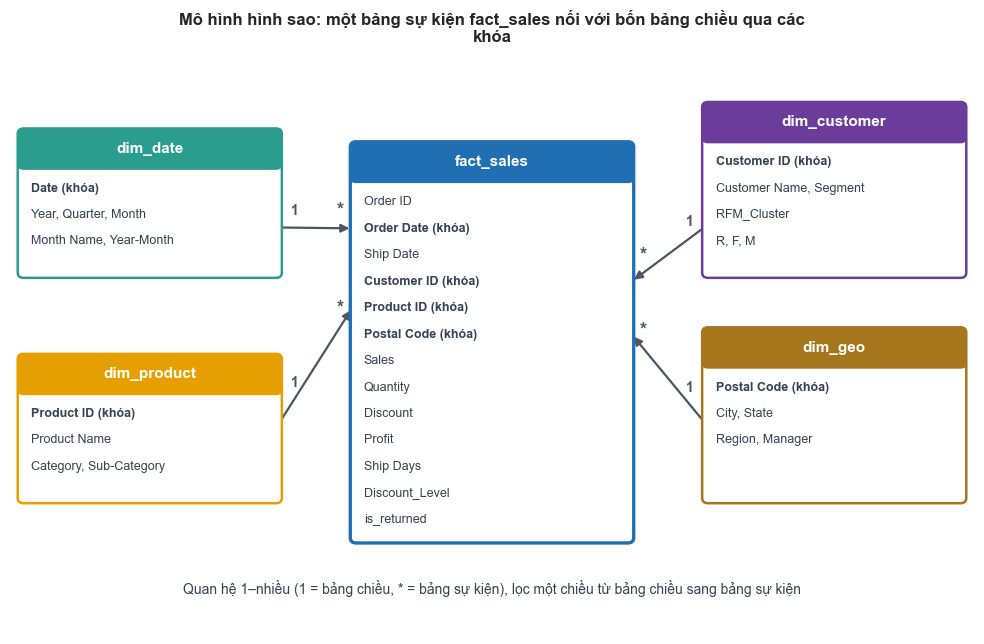

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/5_1_star_schema.png


In [5]:
def hop(ax, x, y, w, h, ten, cot, mau, dam=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.06", fc="white", ec=mau, lw=2.4 if dam else 1.8, zorder=2))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.42), w, 0.42, boxstyle="round,pad=0.02,rounding_size=0.06", fc=mau, ec=mau, zorder=3))
    ax.text(x + w / 2, y + h - 0.21, ten, ha="center", va="center", color="white", fontsize=11, fontweight="bold", zorder=4)
    for i, c in enumerate(cot):
        ax.text(x + 0.12, y + h - 0.66 - i * 0.30, c, ha="left", va="center", fontsize=9, color=INK, zorder=4,
                fontweight="bold" if c.endswith("(khóa)") else "normal")

fig, ax = plt.subplots(figsize=(10, 6.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 6.6); ax.axis("off")
hop(ax, 3.55, 1.05, 2.9, 4.5, "fact_sales", ["Order ID", "Order Date (khóa)", "Ship Date", "Customer ID (khóa)", "Product ID (khóa)", "Postal Code (khóa)",
                                              "Sales", "Quantity", "Discount", "Profit", "Ship Days", "Discount_Level", "is_returned"], FOCUS, dam=True)
hop(ax, 0.1, 4.05, 2.7, 1.65, "dim_date", ["Date (khóa)", "Year, Quarter, Month", "Month Name, Year-Month"], "#2A9D8F")
hop(ax, 0.1, 1.5, 2.7, 1.65, "dim_product", ["Product ID (khóa)", "Product Name", "Category, Sub-Category"], "#E69F00")
hop(ax, 7.2, 4.05, 2.7, 1.95, "dim_customer", ["Customer ID (khóa)", "Customer Name, Segment", "RFM_Cluster", "R, F, M"], "#6A3D9A")
hop(ax, 7.2, 1.5, 2.7, 1.95, "dim_geo", ["Postal Code (khóa)", "City, State", "Region, Manager"], "#A6761D")
def noi(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#4B5563", lw=1.6, shrinkA=2, shrinkB=2), zorder=1)
    ax.text(x0 + (x1 - x0) * 0.20, y0 + (y1 - y0) * 0.20 + 0.14, "1", fontsize=10, fontweight="bold", color="#4B5563", ha="center")
    ax.text(x0 + (x1 - x0) * 0.84, y0 + (y1 - y0) * 0.84 + 0.14, "*", fontsize=13, fontweight="bold", color="#4B5563", ha="center")
noi(2.8, 4.6, 3.55, 4.59); noi(2.8, 2.4, 3.55, 3.69); noi(7.2, 4.6, 6.45, 3.99); noi(7.2, 2.4, 6.45, 3.39)
ax.text(5, 0.45, "Quan hệ 1–nhiều (1 = bảng chiều, * = bảng sự kiện), lọc một chiều từ bảng chiều sang bảng sự kiện", ha="center", fontsize=10, color=INK)
ax.set_title("Mô hình hình sao: một bảng sự kiện fact_sales nối với bốn bảng chiều qua các khóa", fontsize=12)
fig.tight_layout()
luu(fig, "5_1_star_schema")

## Phần A2. Dashboard HTML dự phòng (Plotly)

### Bước 4. Gói dữ liệu và ghép vào mẫu HTML
Dữ liệu ở mức dòng được mã hóa thành các mảng số nguyên/thực nhỏ gọn và nhúng thẳng vào file HTML cùng thư viện Plotly.js, nên file chạy được **không cần internet**. Bộ lọc Năm/Region/Category tính lại mọi biểu đồ bằng JavaScript.

In [6]:
from plotly.offline import get_plotlyjs

ABBR = {"Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
        "District of Columbia": "DC", "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
        "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
        "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
        "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI",
        "South Carolina": "SC", "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
        "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY"}
# Vị trí ô (cột, hàng) của lưới bản đồ theo bang, xấp xỉ vị trí địa lý
LUOI = {"AK": (0, 0), "ME": (10, 0), "VT": (9, 1), "NH": (10, 1),
        "WA": (0, 2), "ID": (1, 2), "MT": (2, 2), "ND": (3, 2), "MN": (4, 2), "IL": (5, 2), "WI": (6, 2), "MI": (7, 2), "NY": (8, 2), "RI": (9, 2), "MA": (10, 2),
        "OR": (0, 3), "NV": (1, 3), "WY": (2, 3), "SD": (3, 3), "IA": (4, 3), "IN": (5, 3), "OH": (6, 3), "PA": (7, 3), "NJ": (8, 3), "CT": (9, 3),
        "CA": (0, 4), "UT": (1, 4), "CO": (2, 4), "NE": (3, 4), "MO": (4, 4), "KY": (5, 4), "WV": (6, 4), "VA": (7, 4), "MD": (8, 4), "DE": (9, 4),
        "AZ": (1, 5), "NM": (2, 5), "KS": (3, 5), "AR": (4, 5), "TN": (5, 5), "NC": (6, 5), "SC": (7, 5), "DC": (8, 5),
        "OK": (3, 6), "LA": (4, 6), "MS": (5, 6), "AL": (6, 6), "GA": (7, 6), "HI": (0, 7), "TX": (3, 7), "FL": (8, 7)}
assert set(LUOI) == set(ABBR.values()) and len(set(LUOI.values())) == 51

NGANH = sorted(df["Category"].unique()); SUB = sorted(df["Sub-Category"].unique()); VUNG = sorted(df["Region"].unique()); SEG = sorted(df["Segment"].unique())
CUM = ["Khách trung thành (VIP)", "Giá trị cao – nguy cơ rời bỏ", "Khách mới / tiềm năng", "Khách ngủ đông"]
BANG = sorted(df["State"].unique()); DV = sorted(df["Discount"].unique()); DL = ["Không", "Thấp", "Cao"]
assert set(cum["Cụm"]) == set(CUM) and set(BANG) <= set(ABBR)
ten_cum = cum.set_index("Customer ID")["Cụm"]
oid = pd.factorize(df["Order ID"])[0]; cid_ma, cid_ten = pd.factorize(df["Customer ID"])
cl_theo_kh = np.array([CUM.index(ten_cum[c]) for c in cid_ten])
lv = lambda lst, s: s.map({v: i for i, v in enumerate(lst)}).astype(int).tolist()
du_lieu = {
    "n": int(len(df)), "years": [2016, 2017, 2018, 2019],
    "cols": {"y": df["Order Date"].dt.year.tolist(), "mi": ((df["Order Date"].dt.year - 2016) * 12 + df["Order Date"].dt.month - 1).tolist(),
             "reg": lv(VUNG, df["Region"]), "cat": lv(NGANH, df["Category"]), "sub": lv(SUB, df["Sub-Category"]), "st": lv(BANG, df["State"]),
             "oid": oid.tolist(), "cid": cid_ma.tolist(), "sales": df["Sales"].round(2).tolist(), "profit": df["Profit"].round(2).tolist(),
             "disc": df["Discount"].tolist(), "dvi": lv(DV, df["Discount"]), "dl": lv(DL, df["Discount_Level"]), "ret": df["is_returned"].astype(int).tolist(),
             "seg": lv(SEG, df["Segment"]), "cl": cl_theo_kh[cid_ma].tolist()},
    "lv": {"reg": VUNG, "cat": NGANH, "sub": SUB, "seg": SEG, "cl": CUM, "dl": DL, "st": BANG},
    "dv": [float(v) for v in DV], "mgr": df.drop_duplicates("Region").set_index("Region")["Manager"].to_dict(),
    "grid": {ten: list(LUOI[ab]) for ten, ab in ABBR.items()}, "abbr": ABBR, "stIdx": {s: i for i, s in enumerate(BANG)},
}
mau = (POWERBI / "dashboard_template.html").read_text(encoding="utf-8")
html = mau.replace("/*PLOTLY*/", get_plotlyjs()).replace("/*DATA*/", json.dumps(du_lieu, ensure_ascii=False, separators=(",", ":")))
(POWERBI / "dashboard_backup.html").write_text(html, encoding="utf-8")
print(f"Đã lưu powerbi/dashboard_backup.html ({len(html) / 1e6:.1f} MB, chạy offline)")

Đã lưu powerbi/dashboard_backup.html (5.4 MB, chạy offline)


### Bước 5. Chụp ảnh tĩnh từng trang (Chrome không giao diện)
Ảnh chụp thật từ file HTML: trang 1 ở năm 2019 (để thẻ KPI có so sánh với 2018), trang 2 và 3 ở toàn bộ 4 năm. Nếu máy không có Chrome, bước này bị bỏ qua.

In [7]:
from PIL import Image

CHROME = next((p for p in ("/Applications/Google Chrome.app/Contents/MacOS/Google Chrome", "/usr/bin/google-chrome", "/usr/bin/chromium",
                            r"C:\Program Files\Google\Chrome\Application\chrome.exe") if Path(p).exists()), None)
TRANG = {1: "page=1&year=2019", 2: "page=2&year=all", 3: "page=3&year=all"}
if CHROME is None:
    print("Không tìm thấy Chrome: bỏ qua bước chụp ảnh (mở powerbi/dashboard_backup.html và chụp màn hình thủ công).")
else:
    for so, tham_so in TRANG.items():
        out = FIGURES / f"5_1_dashboard_trang{so}.png"
        lenh = [CHROME, "--headless", "--disable-gpu", "--hide-scrollbars", "--force-device-scale-factor=2", "--window-size=1120,900",
                "--virtual-time-budget=10000", f"--screenshot={out}", (POWERBI / "dashboard_backup.html").resolve().as_uri() + "#" + tham_so]
        subprocess.run(lenh, check=True, capture_output=True, timeout=120)
        im = Image.open(out).convert("RGB"); a = np.asarray(im)
        nen = np.array([238, 241, 245])
        co_noi_dung = np.where((np.abs(a.astype(int) - nen).sum(axis=2) > 12).any(axis=1))[0]
        cao = min(a.shape[0], int(co_noi_dung.max()) + 24)
        im.crop((0, 0, a.shape[1], cao)).save(out, dpi=(200, 200))
        print(f"Trang {so}: {Image.open(out).size[0]}×{Image.open(out).size[1]} px → {out.name}")

Trang 1: 2240×1625 px → 5_1_dashboard_trang1.png


Trang 2: 2240×1625 px → 5_1_dashboard_trang2.png


Trang 3: 2240×1291 px → 5_1_dashboard_trang3.png


## Phần B. Report: KPI theo năm

### Bước 6. Bảng KPI theo năm 2016–2019 và tăng trưởng YoY
Số đơn, số khách và tỷ lệ đơn bị trả tính ở mức **đơn hàng** (Order ID) và **khách hàng** (Customer ID) khác nhau trong từng năm; AOV = Sales / số đơn.

In [8]:
d = df.assign(Y=df["Order Date"].dt.year)
don = d.groupby(["Y", "Order ID"]).agg(bi_tra=("is_returned", "max")).reset_index()
kpi = d.groupby("Y").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), don=("Order ID", "nunique"), khach=("Customer ID", "nunique"))
kpi["Profit Margin (%)"] = kpi["Profit"] / kpi["Sales"] * 100
kpi["AOV (USD)"] = kpi["Sales"] / kpi["don"]
kpi["Tỷ lệ đơn bị trả (%)"] = don.groupby("Y")["bi_tra"].mean() * 100
for c, ten in (("Sales", "YoY Sales (%)"), ("Profit", "YoY Profit (%)"), ("don", "YoY số đơn (%)"), ("khach", "YoY số khách (%)")):
    kpi[ten] = kpi[c].pct_change() * 100
kpi = kpi.rename(columns={"don": "Số đơn hàng", "khach": "Số khách hàng"})
toan_ky = pd.DataFrame({"Sales": [d["Sales"].sum()], "Profit": [d["Profit"].sum()], "Số đơn hàng": [d["Order ID"].nunique()], "Số khách hàng": [d["Customer ID"].nunique()]}, index=["2016–2019"])
toan_ky["Profit Margin (%)"] = toan_ky["Profit"] / toan_ky["Sales"] * 100
toan_ky["AOV (USD)"] = toan_ky["Sales"] / toan_ky["Số đơn hàng"]
toan_ky["Tỷ lệ đơn bị trả (%)"] = don["bi_tra"].mean() * 100
bang_kpi = pd.concat([kpi.rename(index=str), toan_ky])
cot = ["Sales", "Profit", "Profit Margin (%)", "Số đơn hàng", "Số khách hàng", "AOV (USD)", "Tỷ lệ đơn bị trả (%)", "YoY Sales (%)", "YoY Profit (%)", "YoY số đơn (%)", "YoY số khách (%)"]
bang_kpi = bang_kpi[cot]; bang_kpi.index.name = "Năm"
bang_kpi.round(6).to_csv(REPORTS / "5_2_kpi_by_year.csv", encoding="utf-8-sig")
display(bang_kpi.round(2))
tk = bang_kpi.loc["2016–2019"]
nhan_xet(f"Toàn kỳ, doanh thu đạt {vn(tk['Sales'])} USD, lợi nhuận {vn(tk['Profit'])} USD (biên {pct(tk['Profit Margin (%)'])}) trên {vn(tk['Số đơn hàng'])} đơn, "
         f"AOV {vn(tk['AOV (USD)'], 2)} USD và tỷ lệ đơn bị trả {pct(tk['Tỷ lệ đơn bị trả (%)'])}. Doanh thu tăng {pct(kpi.loc[2018, 'YoY Sales (%)'])} năm 2018 và {pct(kpi.loc[2019, 'YoY Sales (%)'])} năm 2019, "
         f"nhưng AOV giảm từ {vn(kpi.loc[2016, 'AOV (USD)'], 1)} xuống {vn(kpi.loc[2019, 'AOV (USD)'], 1)} USD: tăng trưởng đến từ nhiều đơn hơn, không phải đơn lớn hơn.")

,Sales,Profit,Profit Margin (%),Số đơn hàng,Số khách hàng,AOV (USD),Tỷ lệ đơn bị trả (%),YoY Sales (%),YoY Profit (%),YoY số đơn (%),YoY số khách (%)
Năm,,,,,,,,,,,
2016,483966.13,49556.03,10.24,969,595,499.45,5.47,NaN,NaN,NaN,NaN
2017,470532.51,61618.60,13.10,1038,573,453.31,5.88,-2.78,24.34,7.12,-3.70
2018,609205.60,81795.17,13.43,1315,638,463.27,5.86,29.47,32.74,26.69,11.34
2019,733215.26,93439.27,12.74,1687,693,434.63,6.22,20.36,14.24,28.29,8.62
2016–2019,2296919.49,286409.08,12.47,5009,793,458.56,5.91,NaN,NaN,NaN,NaN


**Nhận xét.** Toàn kỳ, doanh thu đạt 2.296.919 USD, lợi nhuận 286.409 USD (biên 12,5%) trên 5.009 đơn, AOV 458,56 USD và tỷ lệ đơn bị trả 5,9%. Doanh thu tăng 29,5% năm 2018 và 20,4% năm 2019, nhưng AOV giảm từ 499,4 xuống 434,6 USD: tăng trưởng đến từ nhiều đơn hơn, không phải đơn lớn hơn.

### Hình 5.5. Doanh thu theo năm và tăng trưởng YoY

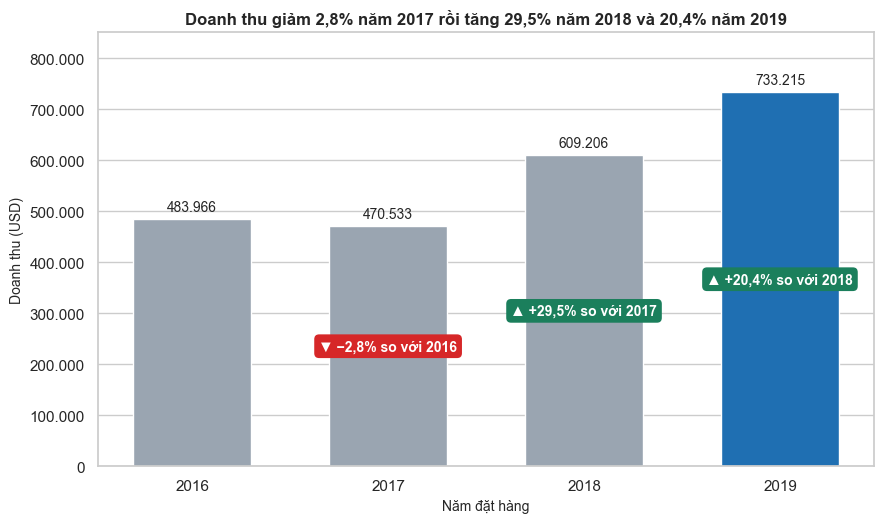

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/5_2_kpi_yoy.png


In [9]:
nam = [2016, 2017, 2018, 2019]
s = kpi.loc[nam, "Sales"]; yoy = kpi.loc[nam, "YoY Sales (%)"]
fig, ax = plt.subplots(figsize=fs(9, 5.4))
ax.bar([str(n) for n in nam], s, color=[NEUTRAL, NEUTRAL, NEUTRAL, FOCUS], width=0.6)
for i, (n, v) in enumerate(zip(nam, s)):
    ax.annotate(f"{vn(v)}", (i, v), ha="center", va="bottom", fontsize=10, xytext=(0, 4), textcoords="offset points")
    if i > 0:
        mau = LOSS if yoy.iloc[i] < 0 else "#1B7F5C"
        ax.annotate(f"{'▲' if yoy.iloc[i] >= 0 else '▼'} {'+' if yoy.iloc[i] >= 0 else ''}{vn(yoy.iloc[i], 1)}% so với {n - 1}", (i, v / 2), ha="center", va="center", fontsize=10,
                    color="white", fontweight="bold", bbox=dict(boxstyle="round,pad=0.35", fc=mau, ec="none"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v)))
ax.set_ylabel("Doanh thu (USD)"); ax.set_xlabel("Năm đặt hàng"); ax.set_ylim(0, s.max() * 1.16)
ax.set_title(f"Doanh thu giảm {vn(abs(yoy.loc[2017]), 1)}% năm 2017 rồi tăng {vn(yoy.loc[2018], 1)}% năm 2018 và {vn(yoy.loc[2019], 1)}% năm 2019", fontsize=12)
fig.tight_layout()
luu(fig, "5_2_kpi_yoy")

### Hình 5.6. Biên lợi nhuận theo năm

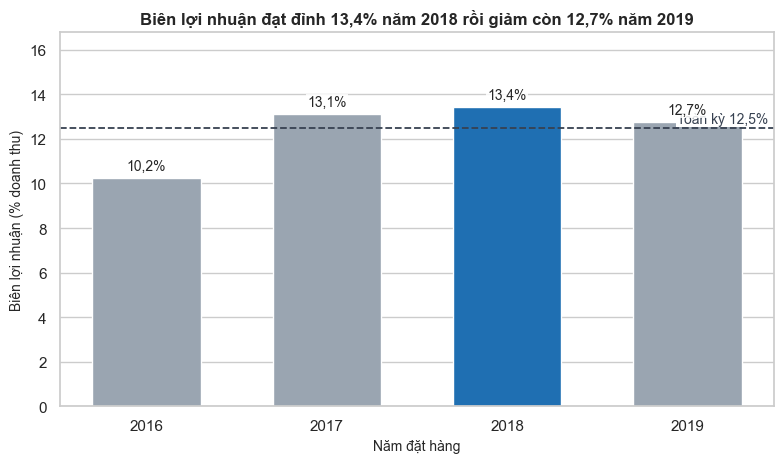

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/5_2_margin_by_year.png


In [10]:
m = kpi.loc[nam, "Profit Margin (%)"]
fig, ax = plt.subplots(figsize=fs(8, 4.8))
ax.bar([str(n) for n in nam], m, color=[NEUTRAL, NEUTRAL, FOCUS, NEUTRAL], width=0.6)
ax.axhline(tk["Profit Margin (%)"], color=INK, ls="--", lw=1.3)
ax.text(3.45, tk["Profit Margin (%)"] + 0.25, f"Toàn kỳ {pct(tk['Profit Margin (%)'])}", ha="right", fontsize=10, color=INK, bbox=dict(fc="white", ec="none", pad=1))
for i, v in enumerate(m):
    ax.annotate(pct(v), (i, v), ha="center", va="bottom", fontsize=10, xytext=(0, 4), textcoords="offset points", zorder=5,
                bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))
ax.set_ylabel("Biên lợi nhuận (% doanh thu)"); ax.set_xlabel("Năm đặt hàng"); ax.set_ylim(0, m.max() * 1.25)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v)))
ax.set_title(f"Biên lợi nhuận đạt đỉnh {pct(m.max())} năm {int(m.idxmax())} rồi giảm còn {pct(m.loc[2019])} năm 2019", fontsize=12)
fig.tight_layout()
luu(fig, "5_2_margin_by_year")

## Số liệu bằng chứng cho mục 5.3 (Decision Making)
Các con số dùng trong 5 quyết định, tính lại từ dữ liệu và từ các bảng kết quả 4.1–4.3, lưu ở `reports/5_3_evidence.csv` để truy vết.

In [11]:
S_TOTAL, N_ROWS = df["Sales"].sum(), len(df)
ev = []
def them(khoa, gia_tri, ghi_chu=""): ev.append({"Khóa": khoa, "Giá trị": gia_tri, "Ghi chú": ghi_chu})

cao = df[df["Discount"] > 0.2]; khong = df[df["Discount"] == 0]
them("disc_cao_dong", len(cao), "Số dòng Discount > 20%"); them("disc_cao_ty_le_dong", len(cao) / N_ROWS * 100, "% số dòng")
them("disc_cao_sales", cao["Sales"].sum(), "Doanh thu nhóm Discount > 20%"); them("disc_cao_ty_le_sales", cao["Sales"].sum() / S_TOTAL * 100, "% doanh thu")
them("disc_cao_profit", cao["Profit"].sum(), "Lợi nhuận nhóm Discount > 20%"); them("disc_khong_profit", khong["Profit"].sum(), "Lợi nhuận nhóm không giảm giá")
them("disc_cao_ty_le_lo", (cao["Profit"] < 0).mean() * 100, "% dòng lỗ trong nhóm Discount > 20%")
for nhom in ("Tables", "Bookcases", "Supplies"):
    x = df[df["Sub-Category"] == nhom]; a, b = x[x["Discount"] <= 0.2], x[x["Discount"] > 0.2]
    them(f"{nhom}_le20_dong", len(a)); them(f"{nhom}_le20_profit", a["Profit"].sum()); them(f"{nhom}_gt20_dong", len(b)); them(f"{nhom}_gt20_profit", b["Profit"].sum())
them("disc_tb_cong_ty", df["Discount"].mean() * 100, "Giảm giá trung bình toàn công ty (%)")
for bang in ("Texas", "Ohio", "Pennsylvania", "Illinois"):
    x = df[df["State"] == bang]
    them(f"{bang}_profit", x["Profit"].sum()); them(f"{bang}_disc_tb", x["Discount"].mean() * 100, "Giảm giá trung bình (%)"); them(f"{bang}_dong", len(x))
tra = pd.read_csv(REPORTS / "4_1_returns_by_region.csv", encoding="utf-8-sig").set_index("Region")
them("west_tra", tra.loc["West", "Tỷ lệ đơn bị trả (%)"], "% đơn bị trả, mức đơn hàng"); them("west_don", int(tra.loc["West", "Số đơn"]))
them("khac_tra_min", tra.drop("West")["Tỷ lệ đơn bị trả (%)"].min()); them("khac_tra_max", tra.drop("West")["Tỷ lệ đơn bị trả (%)"].max())
prof = pd.read_csv(REPORTS / "4_2_cluster_profile.csv", encoding="utf-8-sig", index_col="Cụm")
for t_ in prof.index:
    them(f"cum_{t_}_kh", prof.loc[t_, "Số KH"]); them(f"cum_{t_}_dt", prof.loc[t_, "Tỷ trọng doanh thu (%)"]); them(f"cum_{t_}_rec", prof.loc[t_, "Recency trung vị (ngày)"])
mc = pd.read_csv(REPORTS / "4_3_model_comparison.csv", encoding="utf-8-sig", index_col="Mô hình")
them("xgb_recall", mc.loc["XGBoost", "Recall"]); them("xgb_f1", mc.loc["XGBoost", "F1"]); them("xgb_fn", mc.loc["XGBoost", "FN"]); them("base_fn", mc.loc["Baseline (Discount)", "FN"])
them("xgb_bo_sot", mc.loc["XGBoost", "Tiền lỗ bị bỏ sót (USD)"]); them("base_bo_sot", mc.loc["Baseline (Discount)", "Tiền lỗ bị bỏ sót (USD)"])
them("xgb_giam_bo_sot_pct", (1 - mc.loc["XGBoost", "Tiền lỗ bị bỏ sót (USD)"] / mc.loc["Baseline (Discount)", "Tiền lỗ bị bỏ sót (USD)"]) * 100)
them("xgb_fp", mc.loc["XGBoost", "FP"]); them("base_fp", mc.loc["Baseline (Discount)", "FP"])
bang_ev = pd.DataFrame(ev); bang_ev.round(6).to_csv(REPORTS / "5_3_evidence.csv", index=False, encoding="utf-8-sig")
E = bang_ev.set_index("Khóa")["Giá trị"]
display(bang_ev.round(2))

,Khóa,Giá trị,Ghi chú
0,disc_cao_dong,1392.00,Số dòng Discount > 20%
1,disc_cao_ty_le_dong,13.93,% số dòng
2,disc_cao_sales,362488.78,Doanh thu nhóm Discount > 20%
3,disc_cao_ty_le_sales,15.78,% doanh thu
4,disc_cao_profit,-135364.00,Lợi nhuận nhóm Discount > 20%
5,disc_khong_profit,320987.60,Lợi nhuận nhóm không giảm giá
6,disc_cao_ty_le_lo,96.77,% dòng lỗ trong nhóm Discount > 20%
7,Tables_le20_dong,143.00,
8,Tables_le20_profit,12972.74,
9,Tables_gt20_dong,176.00,


### Bước 7. Đối chiếu với kết quả kỳ vọng

In [12]:
def gan(a, b, dung_sai): return abs(a - b) <= dung_sai
tk = bang_kpi.loc["2016–2019"]; y = bang_kpi
kiem_tra = {
    "Toàn kỳ: Sales ≈ 2.296.919; Profit ≈ 286.409; Margin ≈ 12,5%; 5.009 đơn; AOV ≈ 458,56; trả hàng ≈ 5,9%":
        gan(tk["Sales"], 2296919, 1) and gan(tk["Profit"], 286409, 1) and gan(tk["Profit Margin (%)"], 12.5, 0.05) and tk["Số đơn hàng"] == 5009 and gan(tk["AOV (USD)"], 458.56, 0.005) and gan(tk["Tỷ lệ đơn bị trả (%)"], 5.9, 0.05),
    "Sales theo năm 483.966 / 470.533 / 609.206 / 733.215": all(gan(y.loc[str(n), "Sales"], v, 1) for n, v in zip(nam, [483966, 470533, 609206, 733215])),
    "Sales YoY −2,8% / +29,5% / +20,4%": all(gan(y.loc[str(n), "YoY Sales (%)"], v, 0.05) for n, v in zip(nam[1:], [-2.8, 29.5, 20.4])),
    "Profit theo năm 49.556 / 61.619 / 81.795 / 93.439": all(gan(y.loc[str(n), "Profit"], v, 1) for n, v in zip(nam, [49556, 61619, 81795, 93439])),
    "Profit YoY +24,3% / +32,7% / +14,2%": all(gan(y.loc[str(n), "YoY Profit (%)"], v, 0.05) for n, v in zip(nam[1:], [24.3, 32.7, 14.2])),
    "Margin 10,2% / 13,1% / 13,4% / 12,7%": all(gan(y.loc[str(n), "Profit Margin (%)"], v, 0.05) for n, v in zip(nam, [10.2, 13.1, 13.4, 12.7])),
    "Số đơn 969 / 1.038 / 1.315 / 1.687; YoY +7,1% / +26,7% / +28,3%": all(y.loc[str(n), "Số đơn hàng"] == v for n, v in zip(nam, [969, 1038, 1315, 1687]))
        and all(gan(y.loc[str(n), "YoY số đơn (%)"], v, 0.05) for n, v in zip(nam[1:], [7.1, 26.7, 28.3])),
    "Số khách 595 / 573 / 638 / 693": all(y.loc[str(n), "Số khách hàng"] == v for n, v in zip(nam, [595, 573, 638, 693])),
    "AOV ≈ 499,4 / 453,3 / 463,3 / 434,6": all(gan(y.loc[str(n), "AOV (USD)"], v, 0.05) for n, v in zip(nam, [499.4, 453.3, 463.3, 434.6])),
    "Tỷ lệ đơn bị trả 5,5% / 5,9% / 5,9% / 6,2%": all(gan(y.loc[str(n), "Tỷ lệ đơn bị trả (%)"], v, 0.05) for n, v in zip(nam, [5.5, 5.9, 5.9, 6.2])),
    "Discount > 20%: 1.392 dòng; doanh thu ≈ 362.489 (15,8%); lợi nhuận ≈ −135.364": E["disc_cao_dong"] == 1392 and gan(E["disc_cao_sales"], 362489, 1) and gan(E["disc_cao_ty_le_sales"], 15.8, 0.05) and gan(E["disc_cao_profit"], -135364, 1),
    "Tables: ≤ 20% → 143 dòng, ≈ +12.973; > 20% → 176 dòng, ≈ −30.698": E["Tables_le20_dong"] == 143 and gan(E["Tables_le20_profit"], 12973, 1) and E["Tables_gt20_dong"] == 176 and gan(E["Tables_gt20_profit"], -30698, 1),
    "Texas: giảm giá TB ≈ 37,0% (toàn công ty ≈ 15,6%); lợi nhuận ≈ −25.729": gan(E["Texas_disc_tb"], 37.0, 0.05) and gan(E["disc_tb_cong_ty"], 15.6, 0.05) and gan(E["Texas_profit"], -25729, 1),
    "West trả hàng 11,7%; các vùng khác 2,9–3,3%": gan(E["west_tra"], 11.7, 0.05) and gan(E["khac_tra_min"], 2.9, 0.05) and gan(E["khac_tra_max"], 3.3, 0.05),
    "Cụm nguy cơ rời bỏ: 196 KH; ≈ 37,6% doanh thu; Recency 124,5 ngày": E["cum_Giá trị cao – nguy cơ rời bỏ_kh"] == 196 and gan(E["cum_Giá trị cao – nguy cơ rời bỏ_dt"], 37.6, 0.05) and E["cum_Giá trị cao – nguy cơ rời bỏ_rec"] == 124.5,
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print()
print("Tất cả kết quả khớp kỳ vọng.")
print(f"Lưu ý: kết quả XGBoost thực tế: Recall {E['xgb_recall']:.3f} (số tham chiếu trong đề bài: 0,845), tiền lỗ bị bỏ sót giảm {E['xgb_giam_bo_sot_pct']:.1f}% (đề bài: ≈ 51%).")

ĐẠT  – Toàn kỳ: Sales ≈ 2.296.919; Profit ≈ 286.409; Margin ≈ 12,5%; 5.009 đơn; AOV ≈ 458,56; trả hàng ≈ 5,9%
ĐẠT  – Sales theo năm 483.966 / 470.533 / 609.206 / 733.215
ĐẠT  – Sales YoY −2,8% / +29,5% / +20,4%
ĐẠT  – Profit theo năm 49.556 / 61.619 / 81.795 / 93.439
ĐẠT  – Profit YoY +24,3% / +32,7% / +14,2%
ĐẠT  – Margin 10,2% / 13,1% / 13,4% / 12,7%
ĐẠT  – Số đơn 969 / 1.038 / 1.315 / 1.687; YoY +7,1% / +26,7% / +28,3%
ĐẠT  – Số khách 595 / 573 / 638 / 693
ĐẠT  – AOV ≈ 499,4 / 453,3 / 463,3 / 434,6
ĐẠT  – Tỷ lệ đơn bị trả 5,5% / 5,9% / 5,9% / 6,2%
ĐẠT  – Discount > 20%: 1.392 dòng; doanh thu ≈ 362.489 (15,8%); lợi nhuận ≈ −135.364
ĐẠT  – Tables: ≤ 20% → 143 dòng, ≈ +12.973; > 20% → 176 dòng, ≈ −30.698
ĐẠT  – Texas: giảm giá TB ≈ 37,0% (toàn công ty ≈ 15,6%); lợi nhuận ≈ −25.729
ĐẠT  – West trả hàng 11,7%; các vùng khác 2,9–3,3%
ĐẠT  – Cụm nguy cơ rời bỏ: 196 KH; ≈ 37,6% doanh thu; Recency 124,5 ngày

Tất cả kết quả khớp kỳ vọng.
Lưu ý: kết quả XGBoost thực tế: Recall 0.853 (số tham 